In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jax.scipy.stats import multivariate_normal

In [3]:
rng = np.random.default_rng(seed=42)

In [4]:
# def proposal_distribution(x, mu, Sigma):
#     return multivariate_normal.pdf(x, mean=mu, cov=Sigma)

# def sampling_momentum_dist(mu,Sigma,N):
#     L = jnp.linalg.cholesky(Sigma)
#     z = rng.standard_normal((N,2))
#     return z @ L.T + mu.T

def target_banana(x, b=0.1, sigma=2.0):
    x = jnp.atleast_2d(x)
    x1, x2 = x[:, 0], x[:, 1]
    y1 = x1
    y2 = x2 + b * (x1**2) - b * (sigma**2)
    unwarped = jnp.column_stack([y1, y2])
    covariance = jnp.diag(jnp.array([sigma**2, 1.0]))

    return multivariate_normal.pdf(unwarped,mean=jnp.zeros(2),cov=covariance)


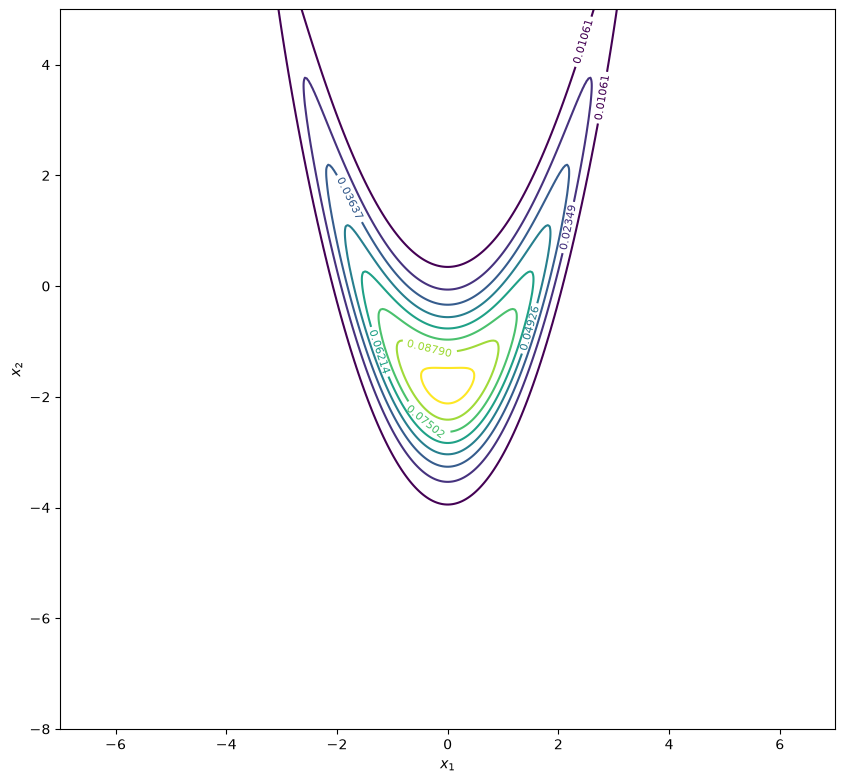

In [5]:
rng = np.random.default_rng(42)

N = 10000
b = -0.8
sigma = 1.5

y = rng.multivariate_normal(
    mean=[0, 0],
    cov=[[sigma**2, 0], [0, 1]],
    size=N
)

x = np.column_stack([
    y[:, 0],
    y[:, 1] - b * (y[:, 0]**2 - sigma**2)
])

x1 = np.linspace(-7, 7, 400)
x2 = np.linspace(-8, 5, 400)

X1, X2 = np.meshgrid(x1, x2)
points = np.column_stack([X1.ravel(), X2.ravel()])
Z = target_banana(points, b=b, sigma=sigma).reshape(X1.shape)

fig, ax = plt.subplots(figsize=(10, 10))

levels = np.linspace(0.1, 0.95, 8) * Z.max()   
contours = ax.contour(X1, X2, Z, levels=levels, cmap="viridis")


ax.clabel(contours, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_xlim(-7, 7)
ax.set_ylim(-8, 5)
ax.set_aspect("equal", adjustable="box")

plt.show()

In [6]:
M = jnp.eye(2)
M_inv = jnp.linalg.inv(M)
L_chol = jnp.linalg.cholesky(M)

def V(theta):                     
    y1 = theta[0]
    y2 = theta[1] + b * theta[0]**2 - b * sigma**2
    return 0.5 * (y1**2 / sigma**2 + y2**2)

grad_V = jax.jit(jax.grad(V))

def K(q):
    return 0.5 * q @ M_inv @ q

def leapfrog(theta, q, eps, L):
    q = q - 0.5 * eps * grad_V(theta)
    for i in range(L):
        theta = theta + eps * (M_inv @ q)
        if i < L - 1:
            q = q - eps * grad_V(theta)
    q = q - 0.5 * eps * grad_V(theta)
    return theta, q

rng = np.random.default_rng(42)
eps, L = 0.2, 25
theta = jnp.zeros(2)
chain, n_acc = [], 0

for _ in range(5000):
    q0 = L_chol @ rng.standard_normal(2)          
    theta_prop, q_prop = leapfrog(theta, q0, eps, L)
    H0 = V(theta) + K(q0)
    H1 = V(theta_prop) + K(q_prop)
    if np.log(rng.uniform()) < H0 - H1:           
        theta = theta_prop
        n_acc += 1
    chain.append(np.array(theta))                 

chain = np.array(chain)
print("acceptance rate:", n_acc / len(chain))

acceptance rate: 0.9838


In [24]:
chain = np.array(chain).squeeze()

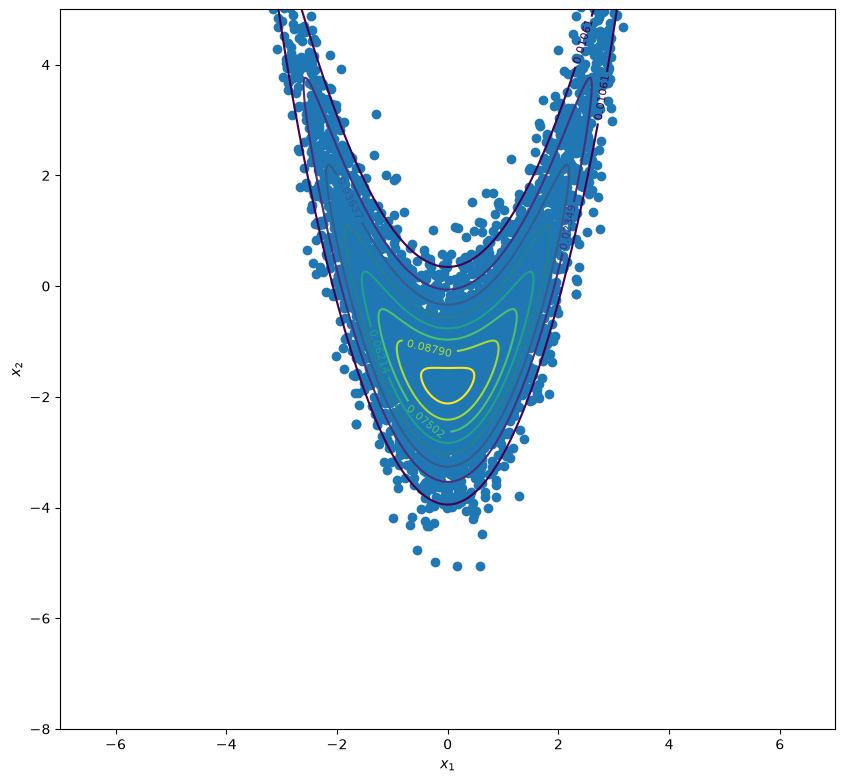

In [7]:
y = rng.multivariate_normal(
    mean=[0, 0],
    cov=[[sigma**2, 0], [0, 1]],
    size=N
)

x = np.column_stack([
    y[:, 0],
    y[:, 1] - b * (y[:, 0]**2 - sigma**2)
])

# Construct grid covering the samples
x1 = np.linspace(-7, 7, 400)
x2 = np.linspace(-8, 5, 400)

X1, X2 = np.meshgrid(x1, x2)

# Evaluate the density at each grid point
points = np.column_stack([X1.ravel(), X2.ravel()])
Z = target_banana(points, b=b, sigma=sigma).reshape(X1.shape)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

levels = np.linspace(0.1, 0.95, 8) * Z.max()   
contours = ax.contour(X1, X2, Z, levels=levels, cmap="viridis")

ax.clabel(contours, inline=True, fontsize=8)

ax.scatter(chain[:,0], chain[:,1])

ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_xlim(-7, 7)
ax.set_ylim(-8, 5)
ax.set_aspect("equal", adjustable="box")

# ax.legend()

plt.show()

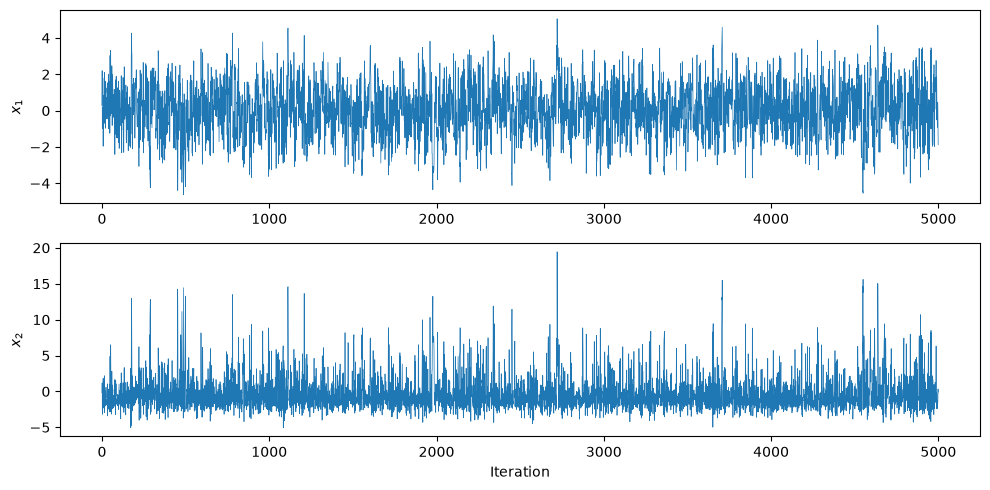

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5))

ax[0].plot(chain[:, 0], lw=0.5)
ax[0].set_ylabel(r"$x_1$")

ax[1].plot(chain[:, 1], lw=0.5)
ax[1].set_ylabel(r"$x_2$")
ax[1].set_xlabel("Iteration")

plt.tight_layout()
plt.show()